# Анализ стационарности и волатильности финансовых временных рядов

Это продолжение первоначального EDA из [`eda.ipynb`](./eda.ipynb). В исходном исследовании были выбраны **10 акций с наибольшим средним денежным оборотом (Average Dollar Volume) за декабрь 2009 года** среди компаний исторического состава S&P 500, а затем собраны дневные котировки за **2010–2025 годы**.

Здесь я изучил два вопроса:

1. **Стационарность:** можно ли считать статистические свойства цен и доходностей устойчивыми во времени? Как меняется результат после перехода от цен к логарифмическим доходностям?
2. **Волатильность:** насколько сильно колеблются доходности разных акций, как меняется их изменчивость по годам и есть ли признаки её зависимости от прошлых наблюдений?

Сначала посмотрим на ряды визуально, затем применим **ADF и KPSS**, а после исследуем историческую и скользящую волатильность и проверим **ARCH-эффекты**.

# 1. Подготовка данных

## 1.1. Загрузка истории торгов

Используем те же тикеры, что были получены в eda.ipynb: `AAPL`, `BAC`, `C`, `AMZN`, `GOOG`, `XOM`, `WFC`, `GS`, `MSFT`, `JPM`. Повторный отбор по ликвидности здесь не выполняется.

С помощью `yfinance` запрашиваем дневные **OHLCV**-котировки с 1 января 2010 года по 31 декабря 2025 года включительно. При `auto_adjust=False` получаем отдельное поле `Adj Close`: скорректированную цену закрытия. Именно его буду использовать в дальнейших расчётах доходностей, чтобы лучше учитывать корпоративные действия, в том числе дивидендные корректировки.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

TICKERS = [
    "AAPL",
    "BAC",
    "C",
    "AMZN",
    "GOOG",
    "XOM",
    "WFC",
    "GS",
    "MSFT",
    "JPM",
]

START_DATE = "2010-01-01"
END_DATE = "2026-01-01"

data = yf.download(
    TICKERS,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=False,
    progress=False,
)

print("Размер датасета:", data.shape)

display(data.head())

Размер датасета: (4024, 60)


Price      Adj Close                                                       \
Ticker          AAPL    AMZN        BAC          C       GOOG          GS   
Date                                                                        
2010-01-04  6.400959  6.6950  11.977126  24.716984  15.463772  128.756760   
2010-01-05  6.412027  6.7345  12.366434  25.662046  15.395673  131.033096   
2010-01-06  6.310036  6.6125  12.511475  26.461712  15.007569  129.634598   
2010-01-07  6.298368  6.5000  12.923693  26.534420  14.658199  132.171326   
2010-01-08  6.340244  6.6760  12.809189  26.098230  14.853610  129.671783   

Price                                                   ...     Volume  \
Ticker            JPM       MSFT        WFC        XOM  ...       AAPL   
Date                                                    ...              
2010-01-04  28.012623  22.984238  17.629484  37.136810  ...  493729600   
2010-01-05  28.555227  22.991657  18.113464  37.281818  ...  601904800   
2010-01-06  28.712114  22.850565  18.139280  37.604057  ...  552160000   
2010-01-07  29.280872  22.612925  18.797470  37.485901  ...  477131200   
2010-01-08  29.208958  22.768879  18.623251  37.335514  ...  447610800   

Price                                                                      \
Ticker           AMZN        BAC         C       GOOG        GS       JPM   
Date                                                                        
2010-01-04  151998000  180845200  40679350   78541293   9135000  35460500   
2010-01-05  177038000  209521300  66861710  120638494  11659400  41208300   
2010-01-06  143576000  205257900  67433890  159744526   7381100  27729000   
2010-01-07  220604000  320868400  67245190  257533695   8727400  44864700   
2010-01-08  196610000  220104700  62409770  189680313   7268100  33110100   

Price                                     
Ticker          MSFT       WFC       XOM  
Date                                      
2010-01-04  38409100  39335700  27809100  
2010-01-05  49749600  55416000  30174700  
2010-01-06  58182400  33237000  35044700  
2010-01-07  50559700  61649000  27192100  
2010-01-08  51197400  35508700  24891800  

[5 rows x 60 columns]

Получилась таблица размером 4 024 строки × 60 столбцов: одна строка на торговую дату и шесть показателей на каждую из десяти акций (`Open`, `High`, `Low`, `Close`, `Adj Close`, `Volume`).

## 1.2. Подготовка рядов для статистического анализа

Дальше оставим только `Adj Close` и построим три представления данных:

- **Скорректированная цена:** $P_t$ — уровень цены в торговый день $t$.
- **Логарифм цены:** $L_t=\ln(P_t)$ — преобразованный ряд уровней.
- **Дневная логарифмическая доходность:**

$$
r_t=\ln\left(\frac{P_t}{P_{t-1}}\right)=\ln(P_t)-\ln(P_{t-1}).
$$

Логарифмирование меняет масштаб цены, а вычисление первой разности логарифмов убирает её уровень и переводит задачу к относительным изменениям между соседними торговыми днями. Для первой даты доходность не определяется: в данных нет предшествующей цены.

In [ ]:
prices = data["Adj Close"].reindex(columns=TICKERS)
prices = prices.sort_index()
log_prices = np.log(prices.where(prices > 0))
log_returns = log_prices.diff()

## 1.3. Первичная проверка качества

Перед тестами проверим, сколько наблюдений есть по каждому тикеру, имеются ли пропуски или неположительные значения цены и совпадают ли границы доступного периода.

In [ ]:
quality = pd.DataFrame({
    "Observations": prices.count(),
    "Missing": prices.isna().sum(),
    "Non-positive": (prices <= 0).sum(),
    "First date": prices.apply(
        lambda x: x.first_valid_index()
    ),
    "Last date": prices.apply(
        lambda x: x.last_valid_index()
    ),
})

display(quality)

,Observations,Missing,Non-positive,First date,Last date
Ticker,,,,,
AAPL,4024,0,0,2010-01-04,2025-12-31
BAC,4024,0,0,2010-01-04,2025-12-31
C,4024,0,0,2010-01-04,2025-12-31
AMZN,4024,0,0,2010-01-04,2025-12-31
GOOG,4024,0,0,2010-01-04,2025-12-31
XOM,4024,0,0,2010-01-04,2025-12-31
WFC,4024,0,0,2010-01-04,2025-12-31
GS,4024,0,0,2010-01-04,2025-12-31
MSFT,4024,0,0,2010-01-04,2025-12-31


У каждой акции есть 4 024 ценовых наблюдения, начиная с 4 января 2010 года и заканчивая 31 декабря 2025 года. В загруженной таблице не выявлено пропущенных и неположительных скорректированных цен. После вычисления первой разности логарифмов остаётся 4 023 дневные доходности на компанию.

# 2. Анализ стационарности

Стационарность предполагает постоянство безусловного среднего и безусловной дисперсии, а также зависимость ковариации наблюдений только от расстояния между ними (лага).

Цены акций часто содержат долгосрочную динамику, тогда как доходности могут колебаться около более устойчивого среднего. Проверим, насколько это соответствует нашим данным.

## 2.1. Скорректированная цена Apple

Начнём с `AAPL` как примера. График показывает уровень `Adj Close`, а не доходность от инвестирования за период.

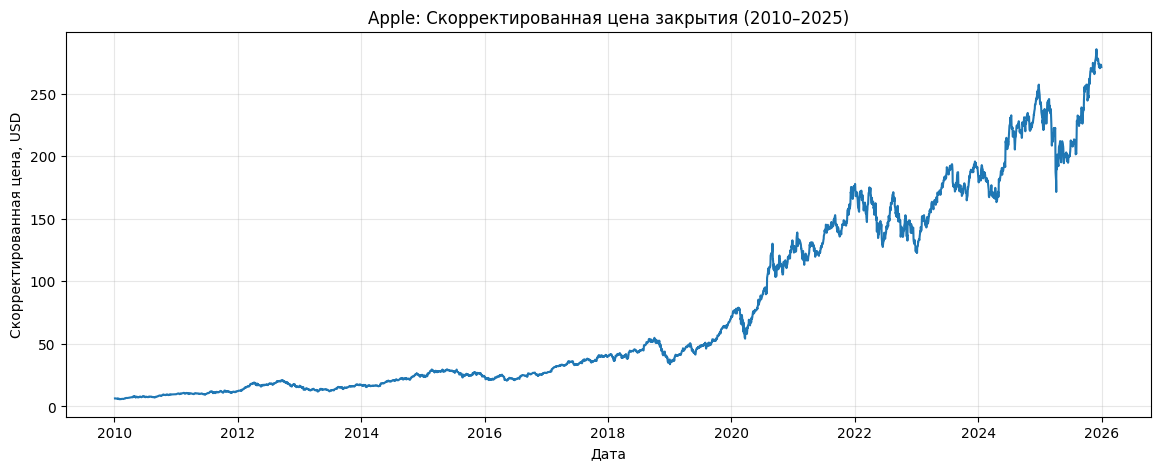

In [ ]:
apple_prices = prices["AAPL"]

plt.figure(figsize=(14, 5))

plt.plot(
    apple_prices.index,
    apple_prices,
)

plt.title("Apple: Скорректированная цена закрытия (2010–2025)")
plt.xlabel("Дата")
plt.ylabel("Скорректированная цена, USD")

plt.grid(alpha=0.3)
plt.show()

На графике заметен выраженный долгосрочный рост уровня скорректированной цены, сопровождающийся просадками и изменением масштаба колебаний. По одному графику нельзя установить наличие единичного корня, но заметно, что ряд не колеблется около одного уровня.

## 2.2. Дневные логарифмические доходности Apple

Теперь посмотрим на изменение логарифма цены между двумя соседними торговыми днями. Нулевой уровень обозначен пунктиром.

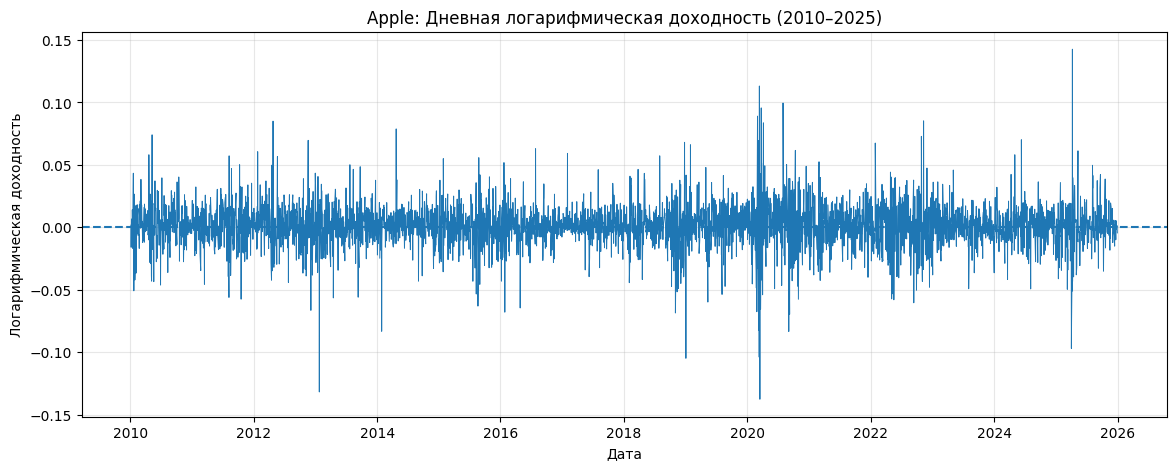

In [ ]:
apple_returns = log_returns["AAPL"].dropna()

plt.figure(figsize=(14, 5))

plt.plot(
    apple_returns.index,
    apple_returns,
    linewidth=0.7,
)

plt.axhline(
    y=0,
    linestyle="--",
)

plt.title("Apple: Дневная логарифмическая доходность (2010–2025)")
plt.xlabel("Дата")
plt.ylabel("Логарифмическая доходность")

plt.grid(alpha=0.3)
plt.show()

Доходности колеблются преимущественно вокруг нуля, но время от времени возникают большие положительные и отрицательные движения. Видны участки с более частыми сильными колебаниями.

## 2.3. Скользящее среднее и стандартное отклонение

Используем окно в 252 торговых дня (примерно один биржевой год). Для каждого момента времени вычисляем среднее и стандартное отклонение доходностей за последние 252 наблюдения:

$$
\bar r_t^{(252)}=\frac{1}{252}\sum_{i=0}^{251}r_{t-i},
\qquad
s_t^{(252)}=\operatorname{std}(r_{t-251},\ldots,r_t).
$$

Первая линия помогает изучить изменения локального среднего, вторая — локального разброса доходностей. Скользящее стандартное отклонение здесь ещё дневное; ниже, в разделе о волатильности, переведём его в годовой масштаб.

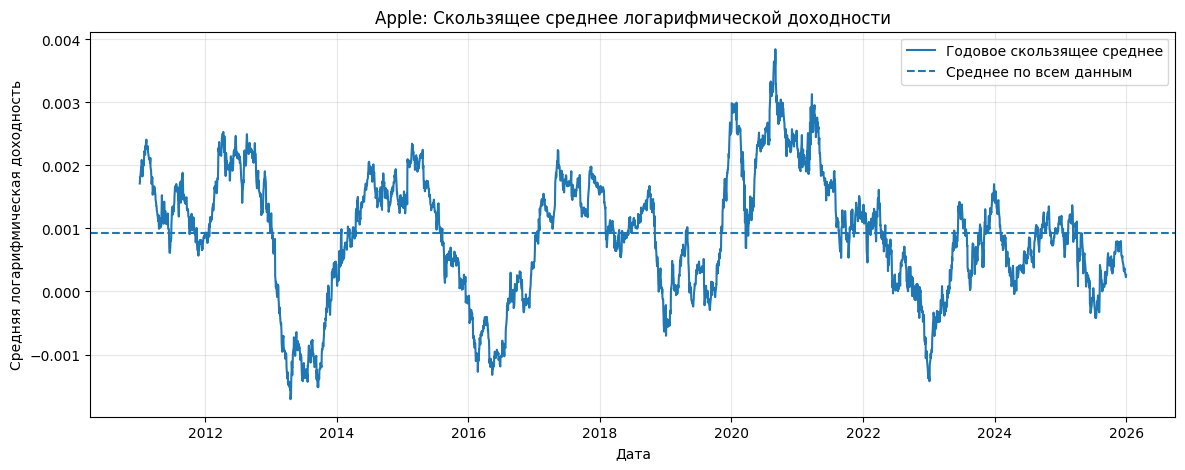

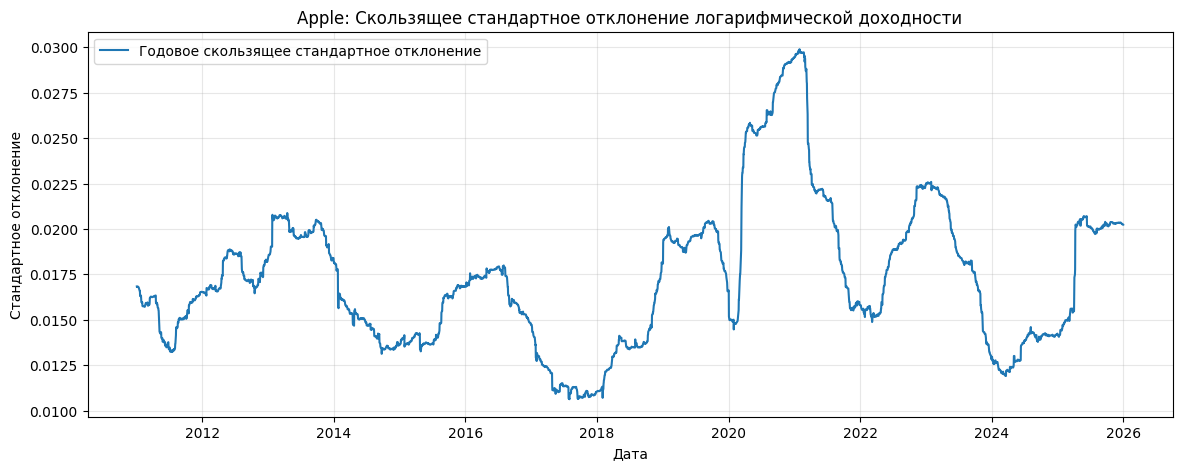

In [ ]:
WINDOW = 252

rolling_mean = apple_returns.rolling(
    window=WINDOW
).mean()

rolling_std = apple_returns.rolling(
    window=WINDOW
).std()

plt.figure(figsize=(14, 5))

plt.plot(
    rolling_mean.index,
    rolling_mean,
    label="Годовое скользящее среднее"
)

plt.axhline(
    apple_returns.mean(),
    linestyle="--",
    label="Среднее по всем данным"
)

plt.title("Apple: Скользящее среднее логарифмической доходности")
plt.xlabel("Дата")
plt.ylabel("Средняя логарифмическая доходность")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(14, 5))

plt.plot(
    rolling_std.index,
    rolling_std,
    label="Годовое скользящее стандартное отклонение"
)

plt.title("Apple: Скользящее стандартное отклонение логарифмической доходности")
plt.xlabel("Дата")
plt.ylabel("Стандартное отклонение")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

По графикам видно, что скользящее среднее Apple меняет знак на отдельных участках. Скользящее стандартное отклонение также неодинаково: оно было сравнительно низким около 2017 года и заметно повысилось в 2020–2021 годах, но это только наблюдаемые изменения выборочных оценок

## 2.4. Формальная проверка: ADF и KPSS

Проверим для всех десяти компаний три ряда: `Adjusted Price`, `Log Price` и `Log Returns`.

| Тест | Нулевая гипотеза $H_0$ | Решение при $p<0.05$ |
|---|---|---|
| **ADF** | В ряду присутствует единичный корень | Отвергаем гипотезу о единичном корне |
| **KPSS** | Ряд стационарен относительно уровня либо линейного тренда | Отвергаем соответствующую гипотезу стационарности |

Для цен и логарифмов цен задаём `regression="ct"` (константа и линейный тренд), для доходностей — `regression="c"` (константа). Число лагов ADF выбирается автоматически по AIC; у KPSS — методом `auto`.

У KPSS табличный диапазон приближённых p-value ограничен. Очень малые p-value ADF, показанные после округления как `0.0000`, также не равны нулю.

In [ ]:
import warnings

import pandas as pd

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

ALPHA = 0.05

SERIES_CONFIG = {
    "Adjusted Price": ("ct", prices),
    "Log Price": ("ct", log_prices),
    "Log Returns": ("c", log_returns),
}

results = []

for ticker in TICKERS:
    for series_name, (regression, dataset) in SERIES_CONFIG.items():

        series = dataset[ticker].dropna()

        adf = adfuller(
            series,
            regression=regression,
            autolag="AIC",
            result_object=True,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", InterpolationWarning)

            kpss_result = kpss(
                series,
                regression=regression,
                nlags="auto",
                result_object=True,
            )

        if kpss_result.statistic > kpss_result.critical_values["1%"]:
            kpss_p_display = "< 0.01"

        elif kpss_result.statistic < min(kpss_result.critical_values.values()):
            kpss_p_display = "> 0.10"

        else:
            kpss_p_display = f"{kpss_result.pvalue:.4f}"

        results.append({
            "Ticker": ticker,
            "Series": series_name,
            "Regression": regression,
            "ADF Statistic": adf.statistic,
            "ADF p-value": adf.pvalue,
            "KPSS Statistic": kpss_result.statistic,
            "KPSS p-value": kpss_result.pvalue,
            "KPSS p-value display": kpss_p_display,
            "ADF Reject H0": adf.pvalue < ALPHA,
            "KPSS Reject H0": (
                kpss_result.statistic >
                kpss_result.critical_values["5%"]
            ),
        })

stationarity_results = pd.DataFrame(results)

display(stationarity_results.round(4))

,Ticker,Series,Regression,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value,KPSS p-value display,ADF Reject H0,KPSS Reject H0
0,AAPL,Adjusted Price,ct,-1.1460,0.9210,2.2108,0.0100,< 0.01,False,True
1,AAPL,Log Price,ct,-2.7972,0.1980,0.6413,0.0100,< 0.01,False,True
2,AAPL,Log Returns,c,-21.4094,0.0000,0.0385,0.1000,> 0.10,True,False
3,BAC,Adjusted Price,ct,-2.2393,0.4678,0.4911,0.0100,< 0.01,False,True
4,BAC,Log Price,ct,-3.0384,0.1217,0.3365,0.0100,< 0.01,False,True
5,BAC,Log Returns,c,-13.7046,0.0000,0.1062,0.1000,> 0.10,True,False
6,C,Adjusted Price,ct,-0.7235,0.9716,0.3129,0.0100,< 0.01,False,True
7,C,Log Price,ct,-2.8193,0.1899,0.3807,0.0100,< 0.01,False,True
8,C,Log Returns,c,-11.9716,0.0000,0.0736,0.1000,> 0.10,True,False
9,AMZN,Adjusted Price,ct,-2.1518,0.5170,0.8439,0.0100,< 0.01,False,True


В детальной таблице каждая строка — одна пара **«акция × представление ряда»**, всего **30 проверок каждого типа**. Столбцы `ADF Reject H0` и `KPSS Reject H0` показывают, отвергается ли соответствующая нулевая гипотеза на уровне значимости 5%.

## 2.5. Краткая сводка

Совместим решения тестов:

- **`Stationary-compatible`** — ADF отвергает единичный корень, KPSS не отвергает стационарность в выбранной спецификации.
- **`Non-stationary-compatible`** — ADF не отвергает единичный корень, KPSS отвергает стационарность.
- **`Inconclusive`** — тесты дают противоречивую или недостаточно определённую картину.


In [ ]:
def interpret_stationarity(row):
    adf_reject = row["ADF Reject H0"]
    kpss_reject = row["KPSS Reject H0"]

    if adf_reject and not kpss_reject:
        return "Stationary-compatible"

    if not adf_reject and kpss_reject:
        return "Non-stationary-compatible"

    return "Inconclusive"


stationarity_results["Interpretation"] = (
    stationarity_results.apply(
        interpret_stationarity,
        axis=1
    )
)

stationarity_summary = stationarity_results.pivot(
    index="Ticker",
    columns="Series",
    values="Interpretation"
)

stationarity_summary = stationarity_summary.reindex(
    columns=[
        "Adjusted Price",
        "Log Price",
        "Log Returns"
    ]
)

display(stationarity_summary)

Series,Adjusted Price,Log Price,Log Returns
Ticker,,,
AAPL,Non-stationary-compatible,Non-stationary-compatible,Stationary-compatible
AMZN,Non-stationary-compatible,Non-stationary-compatible,Stationary-compatible
BAC,Non-stationary-compatible,Non-stationary-compatible,Stationary-compatible
C,Non-stationary-compatible,Non-stationary-compatible,Stationary-compatible
GOOG,Non-stationary-compatible,Stationary-compatible,Stationary-compatible
GS,Non-stationary-compatible,Non-stationary-compatible,Stationary-compatible
JPM,Non-stationary-compatible,Non-stationary-compatible,Stationary-compatible
MSFT,Non-stationary-compatible,Inconclusive,Stationary-compatible
WFC,Non-stationary-compatible,Non-stationary-compatible,Stationary-compatible


**Основные результаты:**

- Скорректированные цены: у 10 из 10 компаний результаты обоих тестов согласуются с нестационарностью, даже при учёте линейного тренда.
- Логарифмические доходности: у 10 из 10 компаний ADF отвергает единичный корень, а KPSS не отвергает стационарность относительно постоянного уровня. Это согласующиеся свидетельства, но не проверка всех условий слабой стационарности.
- Логарифмы цен: у 8 из 10 компаний тесты согласуются с нестационарностью; есть два интересных исключения.

**GOOG:** для логарифма цены ADF даёт $p=0.0367$, а KPSS — $p\approx0.0965$ при спецификации с трендом. Результат согласуется с трендовой стационарностью, но находится достаточно близко к выбранным порогам и нуждается в проверке на подпериодах.

**MSFT:** для логарифма цены ADF даёт $p=0.0405$, а KPSS — $p<0.01$. Оба теста отвергают свои нулевые гипотезы, то есть результат противоречивый; простого ответа «стационарен / нестационарен» здесь нет.


# 3. Анализ волатильности

**Волатильность** описывает величину колебаний доходностей независимо от их направления. В качестве оценки исторической дневной волатильности возьмём выборочное стандартное отклонение логарифмических доходностей:

$$
s_{daily}=\sqrt{\frac{1}{N-1}\sum_{t=1}^{N}(r_t-\bar r)^2}.
$$

Для сопоставления с финансовой практикой переведём оценку в годовой масштаб:

$$
s_{annual}=s_{daily}\sqrt{252}.
$$

## 3.1. Историческая волатильность за весь период

Рассчитаем дневную и годовую волатильность отдельно для каждой из десяти компаний и отсортируем их по убыванию годовой оценки.

In [ ]:
TRADING_DAYS = 252

daily_volatility = log_returns.std(ddof=1)

annual_volatility = daily_volatility * np.sqrt(TRADING_DAYS)

volatility_stats = pd.DataFrame({
    "Daily Volatility (%)": daily_volatility * 100,
    "Annualized Volatility (%)": annual_volatility * 100,
    "Observations": log_returns.count()
})

volatility_stats = volatility_stats.sort_values(
    by="Annualized Volatility (%)",
    ascending=False
)

display(volatility_stats.round(2))

,Daily Volatility (%),Annualized Volatility (%),Observations
Ticker,,,
C,2.13,33.88,4023
BAC,2.10,33.27,4023
AMZN,2.06,32.75,4023
WFC,1.88,29.89,4023
GS,1.81,28.80,4023
AAPL,1.77,28.16,4023
GOOG,1.74,27.58,4023
JPM,1.74,27.57,4023
MSFT,1.61,25.48,4023


По всей выборке 2010–2025 наибольшая годовая экстраполяция исторической волатильности у Citigroup (C) — 33.88%, далее Bank of America (BAC) — 33.27% и Amazon (AMZN) — 32.75%. Наименьшая — у ExxonMobil (XOM) — 24.88%. Для расчёта каждого значения использовано по 4 023 дневные доходности.

## 3.2. Наглядное сравнение активов

Столбчатая диаграмма представляет ту же оценку волатильности.

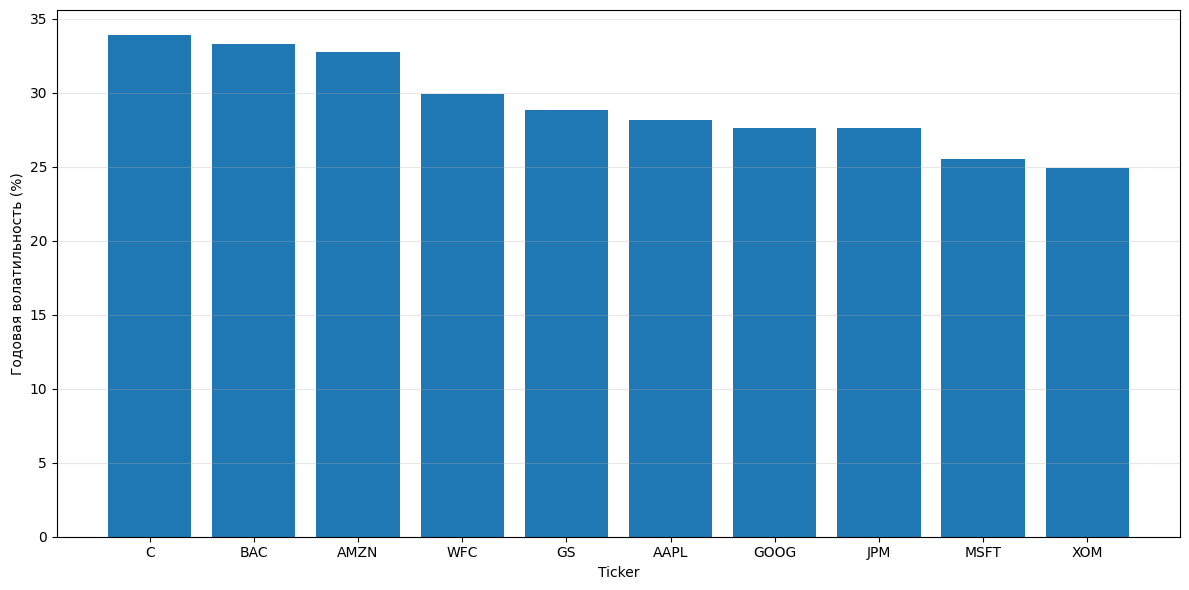

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    volatility_stats.index,
    volatility_stats["Annualized Volatility (%)"]
)

plt.xlabel("Ticker")
plt.ylabel("Годовая волатильность (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

Акции действительно различаются по общему масштабу колебаний: верхнюю часть списка занимают `C`, `BAC` и `AMZN`, нижнюю — `MSFT` и `XOM`. Но эти данные не очень информативны.

## 3.3. Скользящая волатильность: 21, 63 и 252 дня

Вместо одной оценки за всю историю будем повторять расчёт стандартного отклонения для последовательных окон:

- 21 день — приблизительно месяц торгов, быстро реагирует на недавние движения;
- 63 дня — приблизительно квартал, более сглаженная оценка;
- 252 дня — приблизительно год, отражает более продолжительные периоды.

Для каждого окна вычисляем `rolling.std()` и умножаем результат на $\sqrt{252}\cdot100$: все три кривые выражены в годовых процентах, даже если основаны на месяце или квартале наблюдений. Первые значения отсутствуют, пока не накопится полное окно.

In [ ]:
WINDOWS = [21, 63, 252]

rolling_volatility = {}

for window in WINDOWS:

    rolling_volatility[window] = (
        log_returns
        .rolling(window=window, min_periods=window)
        .std()
        * np.sqrt(TRADING_DAYS)
        * 100
    )

## 3.4. Как менялась волатильность Apple


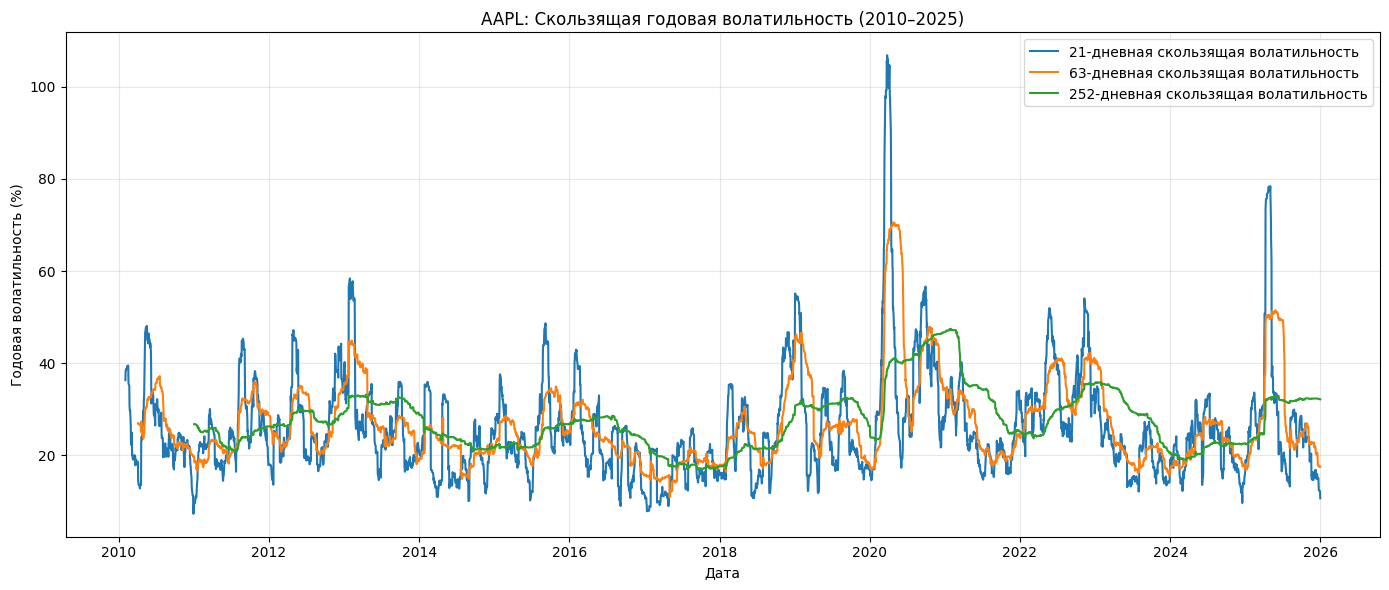

In [ ]:
ticker = "AAPL"

plt.figure(figsize=(14, 6))

for window in WINDOWS:

    plt.plot(
        rolling_volatility[window].index,
        rolling_volatility[window][ticker],
        label=f"{window}-дневная скользящая волатильность"
    )

plt.title(f"{ticker}: Скользящая годовая волатильность (2010–2025)")
plt.xlabel("Дата")
plt.ylabel("Годовая волатильность (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

**Наблюдения по графику:**

- 21-дневная оценка сильнее всего колеблется: в 2020 году она кратковременно превышает 100% в годовом выражении. Это не фактическая доходность или волатильность целого года, а масштабированная оценка за короткое окно.
- 63-дневная оценка реагирует более плавно, но тоже фиксирует периоды сильных колебаний.
- 252-дневная оценка наиболее сглажена и остаётся высокой ещё некоторое время после резкого рыночного движения: сильные изменения долго сохраняются внутри годового окна.

Особенно выделяются периоды около 2020 года и 2022 года; относительно низкую изменчивость видно около 2017 года.

## 3.5. Проверка ARCH-эффектов

Теперь проверим, связаны ли квадраты сегодняшних отклонений доходности с их прошлыми значениями. Для этого используем ARCH-LM-тест на остатках простой модели с постоянным средним:

$$
\varepsilon_t=r_t-\bar r,
\qquad
\varepsilon_t^2=\beta_0+\sum_{i=1}^{q}\beta_i\varepsilon_{t-i}^2+u_t.
$$

Нулевая гипотеза: $\beta_1=\dots=\beta_q=0$, то есть ARCH-эффекты до выбранного порядка отсутствуют. Используем $q=10$ лагов и уровень значимости 5%. Поскольку проверяем сразу десять акций, применим поправку Холма к LM p-value для контроля вероятности хотя бы одного ложноположительного результата внутри этой группы проверок.

Ряд сначала переводится в проценты и центрируется вычитанием выборочного среднего.

In [ ]:
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.multitest import multipletests

ARCH_LAGS = 10
ALPHA = 0.05

arch_results = []

for ticker in TICKERS:

    returns = log_returns[ticker].dropna() * 100

    residuals = returns - returns.mean()

    arch_test = het_arch(
        residuals,
        nlags=ARCH_LAGS,
        result_object=True
    )

    lm_stat = arch_test.lm
    lm_pvalue = arch_test.lmpval
    f_stat = arch_test.fval
    f_pvalue = arch_test.fpval

    arch_results.append({
        "Ticker": ticker,
        "LM Statistic": lm_stat,
        "LM p-value": lm_pvalue,
        "F Statistic": f_stat,
        "F p-value": f_pvalue,
    })

arch_results = pd.DataFrame(arch_results)

reject, p_adjusted, _, _ = multipletests(
    arch_results["LM p-value"],
    alpha=ALPHA,
    method="holm"
)

arch_results["Adjusted p-value"] = p_adjusted
arch_results["ARCH Effect Detected"] = reject

display(
    arch_results.style.format({
        "LM Statistic": "{:.4f}",
        "LM p-value": "{:.2e}",
        "F Statistic": "{:.4f}",
        "F p-value": "{:.2e}",
        "Adjusted p-value": "{:.2e}",
    })
)

,Ticker,LM Statistic,LM p-value,F Statistic,F p-value,Adjusted p-value,ARCH Effect Detected
0,AAPL,410.3758,5.82e-82,45.5869,1.34e-86,1.75e-81,True
1,BAC,873.2167,3.69e-181,111.3011,8.61e-205,2.59e-180,True
2,C,959.9526,7.89e-200,125.8326,5.69e-229,7.10e-199,True
3,AMZN,98.2915,1.20e-16,10.0483,7.38e-17,1.20e-16,True
4,GOOG,111.5826,2.56e-19,11.4459,1.34e-19,5.12e-19,True
5,XOM,854.6545,3.64e-177,108.2949,1.05e-199,2.18e-176,True
6,WFC,1044.1759,5.68e-218,140.7558,3.89e-253,5.68e-217,True
7,GS,843.3723,9.73e-175,106.4849,1.25e-196,4.86e-174,True
8,MSFT,662.4758,7.09e-136,79.1288,8.15e-149,2.84e-135,True
9,JPM,945.7883,8.86e-197,123.4034,5.64e-225,7.08e-196,True


В результате для всех 10 акций скорректированные по Холму p-value существенно меньше 0.05 (`ARCH Effect Detected = True`)

Это означает, что в выбранной тестовой модели обнаружена статистически значимая зависимость квадратов остатков от их прошлых значений. Результат согласуется с кластеризацией волатильности.

## 3.6. Чувствительность ARCH-LM к количеству лагов

Для надежности повторим тест при 5, 10 и 20 лагах, чтобы понять, изменится ли статистическое решение при другой длине зависимости.

In [ ]:
from statsmodels.stats.diagnostic import het_arch

lags_to_check = [5, 10, 20]

robustness_results = []

for ticker in TICKERS:
    returns = log_returns[ticker].dropna() * 100
    residuals = returns - returns.mean()

    for lag in lags_to_check:
        result = het_arch(
            residuals,
            nlags=lag,
            result_object=True
        )

        robustness_results.append({
            "Ticker": ticker,
            "Lags": lag,
            "LM Statistic": result.lm,
            "p-value": result.lmpval,
        })

arch_robustness = pd.DataFrame(robustness_results)

display(
    arch_robustness.pivot(
        index="Ticker",
        columns="Lags",
        values="p-value"
    )
)

Lags,5,10,20
Ticker,,,
AAPL,4.874396e-78,5.820068e-82,5.251949e-77
AMZN,1.026162e-15,1.196928e-16,3.914353e-14
BAC,4.190995e-181,3.694518e-181,1.704739e-179
C,2.924476e-202,7.892888e-200,6.332187e-198
GOOG,2.698176e-19,2.557989e-19,4.284604e-17
GS,2.323383e-173,9.725365e-175,4.674786e-168
JPM,7.939728e-189,8.855153e-197,1.484214e-191
MSFT,5.727401e-129,7.092831e-136,8.238676e-132
WFC,9.118518e-215,5.677687e-218,1.674070e-221


Результат проверки устойчивости. Во всех 30 сочетаниях «акция × число лагов» p-value остаётся крайне малым. Даже самое большое из них значительно меньше 0.05; вывод об обнаружении ARCH-эффектов устойчив к этим трём значениям `nlags`.

Для формального учёта всех дополнительных проверок можно отдельно корректировать p-value уже по всей группе из 30 тестов — здесь их экстремально малые значения не меняют содержательного вывода.

## 3.7. Волатильность по календарным годам

Общая оценка за 2010–2025 годы сглаживает различия между периодами. Поэтому сгруппируем доходности по календарным годам, рассчитаем стандартное отклонение внутри каждого года и снова приведём его к годовому масштабу.

В отличие от скользящего окна, календарные годы не перекрываются. Так мы получим таблицу 16 лет × 10 акций, по которой можно выявить общие и индивидуальные периоды высокой изменчивости.

In [ ]:
yearly_volatility = (
    log_returns
    .resample("YE")
    .std()
    * np.sqrt(TRADING_DAYS)
    * 100
)

yearly_volatility.index = yearly_volatility.index.year

display(yearly_volatility.round(2))

Ticker,AAPL,BAC,C,AMZN,GOOG,XOM,WFC,GS,MSFT,JPM
Date,,,,,,,,,,
2010,26.70,36.75,38.00,32.69,27.85,17.96,33.79,31.16,21.97,30.67
2011,26.25,58.39,53.45,38.63,29.29,25.40,38.79,38.08,23.47,40.49
2012,29.30,38.85,36.28,31.20,23.16,14.85,21.86,28.48,20.70,28.74
2013,28.91,23.50,22.92,26.91,21.31,13.02,15.80,21.51,25.14,19.11
2014,21.67,21.68,20.48,32.82,21.26,16.56,14.05,17.32,18.99,17.86
2015,26.75,25.68,24.31,32.67,28.74,22.49,19.95,22.35,28.03,22.26
2016,23.37,32.22,31.90,29.66,20.06,19.08,23.67,26.89,22.71,24.58
2017,17.53,21.52,17.56,20.49,15.44,11.18,17.74,19.75,14.73,16.22
2018,28.77,24.75,24.06,36.16,28.24,21.97,23.66,25.81,28.24,22.17


Исходя из таблицы:

- 2020 год оказался годом с максимальной волатильностью у 8 из 10 акций. Для `C` показатель достиг 67.85%, для `WFC` — 61.41%, для `AAPL` — 46.68%.
- 2017 год оказался годом с минимальной волатильностью также у 8 из 10 акций. Два исключения — `WFC` и `GS`, у которых минимум приходится на 2014 год.
- Для AMZN и GOOG максимум пришёлся не на 2020-й, а на 2022 год: 50.13% и 38.80% соответственно.

Эти результаты показывают наличие общих периодов изменения волатильности и отдельных различий между компаниями. 2020 год исторически совпадает с пандемией COVID-19 и рыночной нестабильностью. На основе выбранных десяти акций также нельзя делать выводы о всех отраслях рынка.

## 3.8. Пример: годовая волатильность Apple

Построим отдельную столбчатую диаграмму, чтобы наглядно сравнить спокойные и нестабильные календарные годы для Apple.

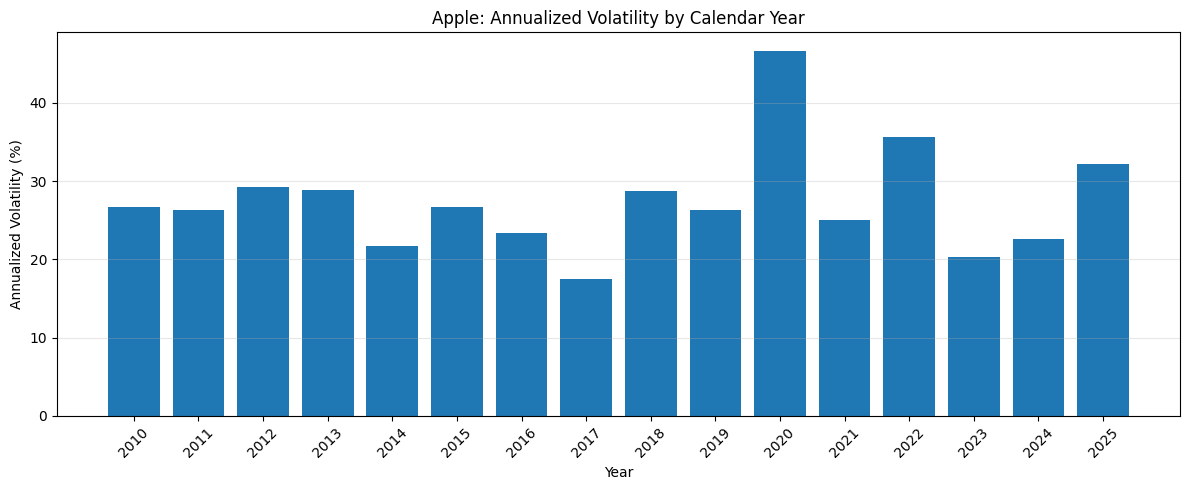

In [ ]:
plt.figure(figsize=(12, 5))

plt.bar(
    yearly_volatility.index,
    yearly_volatility["AAPL"]
)

plt.title("Apple: Annualized Volatility by Calendar Year")
plt.xlabel("Year")
plt.ylabel("Annualized Volatility (%)")

plt.xticks(yearly_volatility.index, rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

Для Apple минимум пришёлся на 2017 год — 17.53%, а максимум — на 2020 год — 46.68%. Таким образом, годовая оценка стандартного отклонения дневных доходностей в 2020 году была примерно в 2.66 раза выше, чем в 2017-м. Повышенные значения также наблюдались в 2022 году (35.63%) и 2025 году (32.21%).

Именно поэтому одна оценка волатильности за 16 лет не описывает одинаково хорошо каждый календарный год.

# 4. Итоговые выводы

1. Уровни цен и доходности ведут себя по-разному. Для всех десяти акций ADF и KPSS согласуются с нестационарностью скорректированных цен; для всех десяти рядов дневных логарифмических доходностей результаты согласуются со стационарностью относительно постоянного уровня в используемых спецификациях тестов.
2. Логарифмирование само по себе не устраняет нестационарность. Для логарифмов цен восьми акций тесты указывают на нестационарность. У `GOOG` результаты согласуются с трендовой стационарностью, у `MSFT` — противоречивы; эти случаи требуют отдельной проверки устойчивости.
3. Общий уровень исторической волатильности различается между компаниями. Наибольшая годовая экстраполяция за весь период — у `C` (33.88%), наименьшая — у `XOM` (24.88%).
4. Историческая волатильность сильно изменяется во времени. Для восьми акций максимум календарной годовой оценки пришёлся на 2020 год, а минимум — на 2017 год. Краткосрочные окна у Apple выявляют ещё более резкие всплески, чем годовые.
5. Есть сильные статистические свидетельства ARCH-эффектов. ARCH-LM отвергает нулевую гипотезу для всех десяти акций; результат сохраняется при 5, 10 и 20 лагах.

